# Классификация автомобилей (Toyota / BMW / Other) 


**Цель работы:** построить модель для классификации изображений автомобилей на 3 категории:
- **Toyota** (класс 0)
- **BMW** (класс 1)
- **Other** — прочие марки: Audi, Mercedes, Ford, Hyundai и т.д. (класс 2)

### План работы
1. Подготовка окружения и импорты
2. Парсинг изображений из интернета (icrawler)
3. Подготовка собственных фотографий
4. Предобработка и очистка данных
5. Формирование датасета и загрузчиков
6. Архитектура модели (ResNet18)
7. Обучение: Transfer Learning + Fine-Tuning
8. Тестирование на отложенной выборке
9. Проверка на собственных фотографиях
10. Анализ граничных случаев
11. Заключение

## Установка необходимых библиотек

In [ ]:
import os
import random
import shutil
import hashlib
import warnings
import time
import re
import functools
from pathlib import Path
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import imagehash

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms.v2 as transforms
import torchvision.models as models
from torchvision.models import resnet18, ResNet18_Weights
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from tqdm import tqdm

# Фиксируем генераторы для воспроизводимости
SEED = 17
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
np.random.seed(SEED)
random.seed(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Устройство: {device}")

# Пути к директориям
BASE_DIR = Path(r"/Users/alenasamsonova/Downloads/samsonova_full")
DATA_DIR = BASE_DIR / "car_classification"
OWN_DIR  = BASE_DIR / "own_photos"
MODEL_DIR = BASE_DIR / "models"

CLASSES = ["toyota", "bmw", "other"]
LABEL_NAMES = ["Toyota", "BMW", "Other"]
N_CLASSES = 3

for folder in [DATA_DIR, MODEL_DIR]:
    for c in CLASSES:
        (folder / c).mkdir(parents=True, exist_ok=True)

print("Рабочие директории готовы.")

Устройство: cpu
Рабочие директории готовы.


---
## Сбор изображений из интернета (icrawler)

Используем Bing Image Search через icrawler для загрузки ~600 фотографий каждого класса.
Для каждой категории подготовлены несколько поисковых запросов, чтобы обеспечить
разнообразие ракурсов и условий съёмки.

In [2]:
from icrawler.builtin import BingImageCrawler

SEARCH_QUERIES = {
    "toyota": [
        "Toyota Corolla road photo", "Toyota Camry city street",
        "Toyota RAV4 parking", "Toyota sedan highway",
        "Toyota SUV urban", "Toyota car driving",
    ],
    "bmw": [
        "BMW 5 series road photo", "BMW 3 series city street",
        "BMW X5 parking lot", "BMW sedan highway",
        "BMW SUV urban", "BMW car driving",
    ],
    "other": [
        "Mercedes car road photo", "Audi car city street",
        "Hyundai car parking", "Ford car highway photo",
        "Volkswagen car driving", "Kia car urban",
        "Honda car street photo", "Mazda sedan road",
    ],
}

IMAGES_PER_QUERY = 100

for cls_name, queries in SEARCH_QUERIES.items():
    target_dir = str(DATA_DIR / cls_name)
    for q in queries:
        crawler = BingImageCrawler(
            storage={"root_dir": target_dir},
            downloader_threads=4,
        )
        crawler.crawl(keyword=q, max_num=IMAGES_PER_QUERY)
        print(f"  [{cls_name}] '{q}' — готово")

# Статистика после загрузки
for cls_name in CLASSES:
    count = len(list((DATA_DIR / cls_name).glob("*")))
    print(f"{cls_name}: {count} файлов загружено")

2026-04-27 16:33:26,818 - INFO - icrawler.crawler - start crawling...
2026-04-27 16:33:26,819 - INFO - icrawler.crawler - starting 1 feeder threads...
2026-04-27 16:33:26,819 - INFO - feeder - thread feeder-001 exit
2026-04-27 16:33:26,819 - INFO - icrawler.crawler - starting 1 parser threads...
2026-04-27 16:33:26,821 - INFO - icrawler.crawler - starting 4 downloader threads...
2026-04-27 16:33:31,822 - INFO - downloader - downloader-004 is waiting for new download tasks
2026-04-27 16:33:31,824 - INFO - downloader - downloader-003 is waiting for new download tasks
2026-04-27 16:33:31,825 - INFO - downloader - downloader-001 is waiting for new download tasks
2026-04-27 16:33:31,825 - INFO - downloader - downloader-002 is waiting for new download tasks
2026-04-27 16:33:32,018 - ERROR - parser - Exception caught when fetching page https://www.bing.com/images/async?q=Toyota Corolla road photo&first=0, error: HTTPSConnectionPool(host='www.bing.com', port=443): Read timed out. (read timeout

  [toyota] 'Toyota Corolla road photo' — готово


2026-04-27 16:34:52,125 - INFO - downloader - downloader-003 is waiting for new download tasks
2026-04-27 16:34:52,126 - INFO - downloader - downloader-002 is waiting for new download tasks
2026-04-27 16:34:52,127 - INFO - downloader - downloader-001 is waiting for new download tasks
2026-04-27 16:34:52,129 - INFO - downloader - downloader-004 is waiting for new download tasks
2026-04-27 16:34:57,128 - INFO - downloader - downloader-001 is waiting for new download tasks
2026-04-27 16:34:57,129 - INFO - downloader - downloader-003 is waiting for new download tasks
2026-04-27 16:34:57,129 - INFO - downloader - downloader-002 is waiting for new download tasks
2026-04-27 16:34:57,130 - INFO - downloader - downloader-004 is waiting for new download tasks
2026-04-27 16:35:02,134 - INFO - downloader - downloader-001 is waiting for new download tasks
2026-04-27 16:35:02,135 - INFO - downloader - downloader-002 is waiting for new download tasks
2026-04-27 16:35:02,135 - INFO - downloader - down

  [toyota] 'Toyota Camry city street' — готово


2026-04-27 16:35:45,960 - INFO - parser - parsing result page https://www.bing.com/images/async?q=Toyota RAV4 parking&first=0
2026-04-27 16:35:45,984 - INFO - downloader - skip downloading file 000001.jpg
2026-04-27 16:35:45,986 - INFO - downloader - skip downloading file 000002.jpg
2026-04-27 16:35:45,987 - INFO - downloader - skip downloading file 000003.jpg
2026-04-27 16:35:45,988 - INFO - downloader - skip downloading file 000004.jpg
2026-04-27 16:35:45,988 - INFO - downloader - skip downloading file 000005.jpg
2026-04-27 16:35:45,989 - INFO - downloader - skip downloading file 000006.jpg
2026-04-27 16:35:45,990 - INFO - downloader - skip downloading file 000007.jpg
2026-04-27 16:35:45,990 - INFO - downloader - skip downloading file 000008.jpg
2026-04-27 16:35:45,991 - INFO - downloader - skip downloading file 000009.jpg
2026-04-27 16:35:45,991 - INFO - downloader - skip downloading file 000010.jpg
2026-04-27 16:35:45,992 - INFO - downloader - skip downloading file 000011.jpg
2026-

...

  [other] 'Kia car urban' — готово


2026-04-27 16:38:15,918 - INFO - parser - parsing result page https://www.bing.com/images/async?q=Honda car street photo&first=0
2026-04-27 16:38:15,943 - INFO - downloader - skip downloading file 000001.jpg
2026-04-27 16:38:15,946 - INFO - downloader - skip downloading file 000002.jpeg
2026-04-27 16:38:15,948 - INFO - downloader - skip downloading file 000003.jpg
2026-04-27 16:38:15,948 - INFO - downloader - skip downloading file 000004.jpg
2026-04-27 16:38:15,949 - INFO - downloader - skip downloading file 000005.jpeg
2026-04-27 16:38:15,950 - INFO - downloader - skip downloading file 000006.jpg
2026-04-27 16:38:15,950 - INFO - downloader - skip downloading file 000007.jpg
2026-04-27 16:38:15,951 - INFO - downloader - skip downloading file 000008.jpeg
2026-04-27 16:38:15,952 - INFO - downloader - skip downloading file 000009.jpg
2026-04-27 16:38:15,952 - INFO - downloader - skip downloading file 000010.jpeg
2026-04-27 16:38:15,954 - INFO - downloader - skip downloading file 000011.jp

  [other] 'Honda car street photo' — готово


2026-04-27 16:38:24,725 - INFO - parser - parsing result page https://www.bing.com/images/async?q=Mazda sedan road&first=0
2026-04-27 16:38:24,742 - INFO - downloader - skip downloading file 000001.jpg
2026-04-27 16:38:24,743 - INFO - downloader - skip downloading file 000002.jpg
2026-04-27 16:38:24,744 - INFO - downloader - skip downloading file 000003.jpg
2026-04-27 16:38:24,745 - INFO - downloader - skip downloading file 000004.jpg
2026-04-27 16:38:24,747 - INFO - downloader - skip downloading file 000005.jpg
2026-04-27 16:38:24,749 - INFO - downloader - skip downloading file 000006.jpg
2026-04-27 16:38:24,750 - INFO - downloader - skip downloading file 000007.jpg
2026-04-27 16:38:24,750 - INFO - downloader - skip downloading file 000008.jpg
2026-04-27 16:38:24,751 - INFO - downloader - skip downloading file 000009.jpg
2026-04-27 16:38:24,751 - INFO - downloader - skip downloading file 000010.jpg
2026-04-27 16:38:24,753 - INFO - downloader - skip downloading file 000011.jpg
2026-04-

  [other] 'Mazda sedan road' — готово
toyota: 599 файлов загружено
bmw: 597 файлов загружено
other: 608 файлов загружено


---
## Собственные фотографии

Собственные фотографии автомобилей были заранее собраны и размещены в директории
`own_photos/{toyota, bmw, other}`. Это снимки в реальных условиях — уличная съёмка,
разные ракурсы, разное освещение.

Проверим наличие и количество файлов:

In [8]:
print ("Мои фотографии:")
for cls_name in CLASSES:
    cls_path = OWN_DIR / cls_name
    if cls_path.exists():
        n_files = len([f for f in cls_path.glob("*") if f.is_file()])
        print(f"  {cls_name}: {n_files} фото")
    else:
        print(f"  {cls_name}: директория не найдена!")

Мои фотографии:
  toyota: 20 фото
  bmw: 18 фото
  other: 38 фото


---
## Очистка и предобработка данных

In [ ]:
def remove_bad_and_duplicates(data_path, class_list, min_dim=(100, 100)):
    """Удаляет битые, слишком мелкие и дублирующиеся изображения."""
    counters = {"corrupt": 0, "tiny": 0, "duplicate": 0}

    for cls in class_list:
        folder = Path(data_path) / cls
        if not folder.exists():
            continue

        seen_hashes = {}
        all_files = sorted(folder.glob("*"))

        for fp in all_files:
            if not fp.is_file():
                continue

            # Проверка целостности
            try:
                im = Image.open(fp)
                im.verify()
                im = Image.open(fp)
            except Exception:
                fp.unlink()
                counters["corrupt"] += 1
                continue

            # Проверка размера
            if im.size[0] < min_dim[0] or im.size[1] < min_dim[1]:
                fp.unlink()
                counters["tiny"] += 1
                continue

            # Дубликаты
            try:
                phash = str(imagehash.phash(im))
                if phash in seen_hashes:
                    fp.unlink()
                    counters["duplicate"] += 1
                else:
                    seen_hashes[phash] = fp
            except:
                pass

    return counters

print("Очистка основного набора данных...")
main_counters = remove_bad_and_duplicates(DATA_DIR, CLASSES)
print(f"  Результат: {main_counters}")

print("Очистка собственных фотографий...")
own_counters = remove_bad_and_duplicates(OWN_DIR, CLASSES)
print(f"  Результат: {own_counters}")

print("\nПосле очистки:")
for cls in CLASSES:
    n1 = len(list((DATA_DIR / cls).glob("*")))
    n2 = len(list((OWN_DIR / cls).glob("*")))
    print(f"  {cls}: основной={n1}, собственные={n2}")

Очистка основного набора данных...
  Результат: {'corrupt': 2, 'tiny': 0, 'duplicate': 13}
Очистка собственных фотографий...
  Результат: {'corrupt': 2, 'tiny': 0, 'duplicate': 3}

После очистки:
  toyota: основной=595, собственные=20
  bmw: основной=591, собственные=18
  other: основной=603, собственные=38


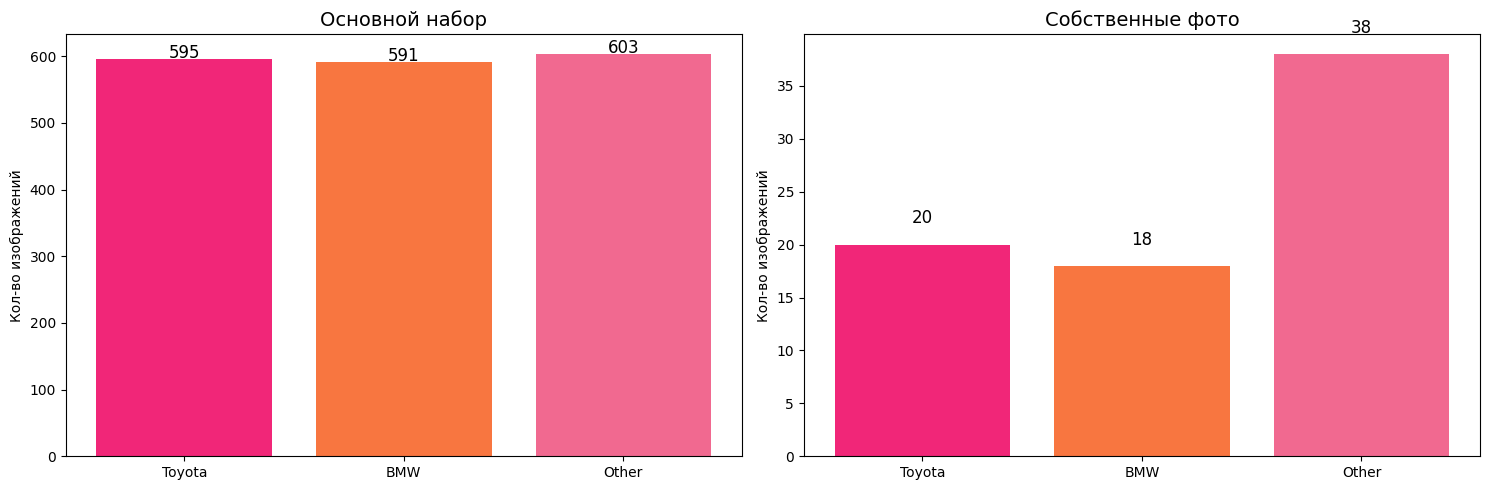

In [ ]:
# Диаграмма распределения по классам
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, (path, label) in zip(axes, [(DATA_DIR, "Основной набор"), (OWN_DIR, "Собственные фото")]):
    nums = {c: len(list((path / c).glob("*"))) for c in CLASSES}
    bars = ax.bar(LABEL_NAMES, nums.values(), color=["#F12678", "#f87640", "#f16990"])
    ax.set_title(label, fontsize=14)
    ax.set_ylabel("Кол-во изображений")
    for b, val in zip(bars, nums.values()):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 2, str(val),
                ha="center", fontsize=12)

plt.tight_layout()
plt.savefig(str(BASE_DIR / "class_distribution.png"), dpi=150, bbox_inches="tight")
plt.show()

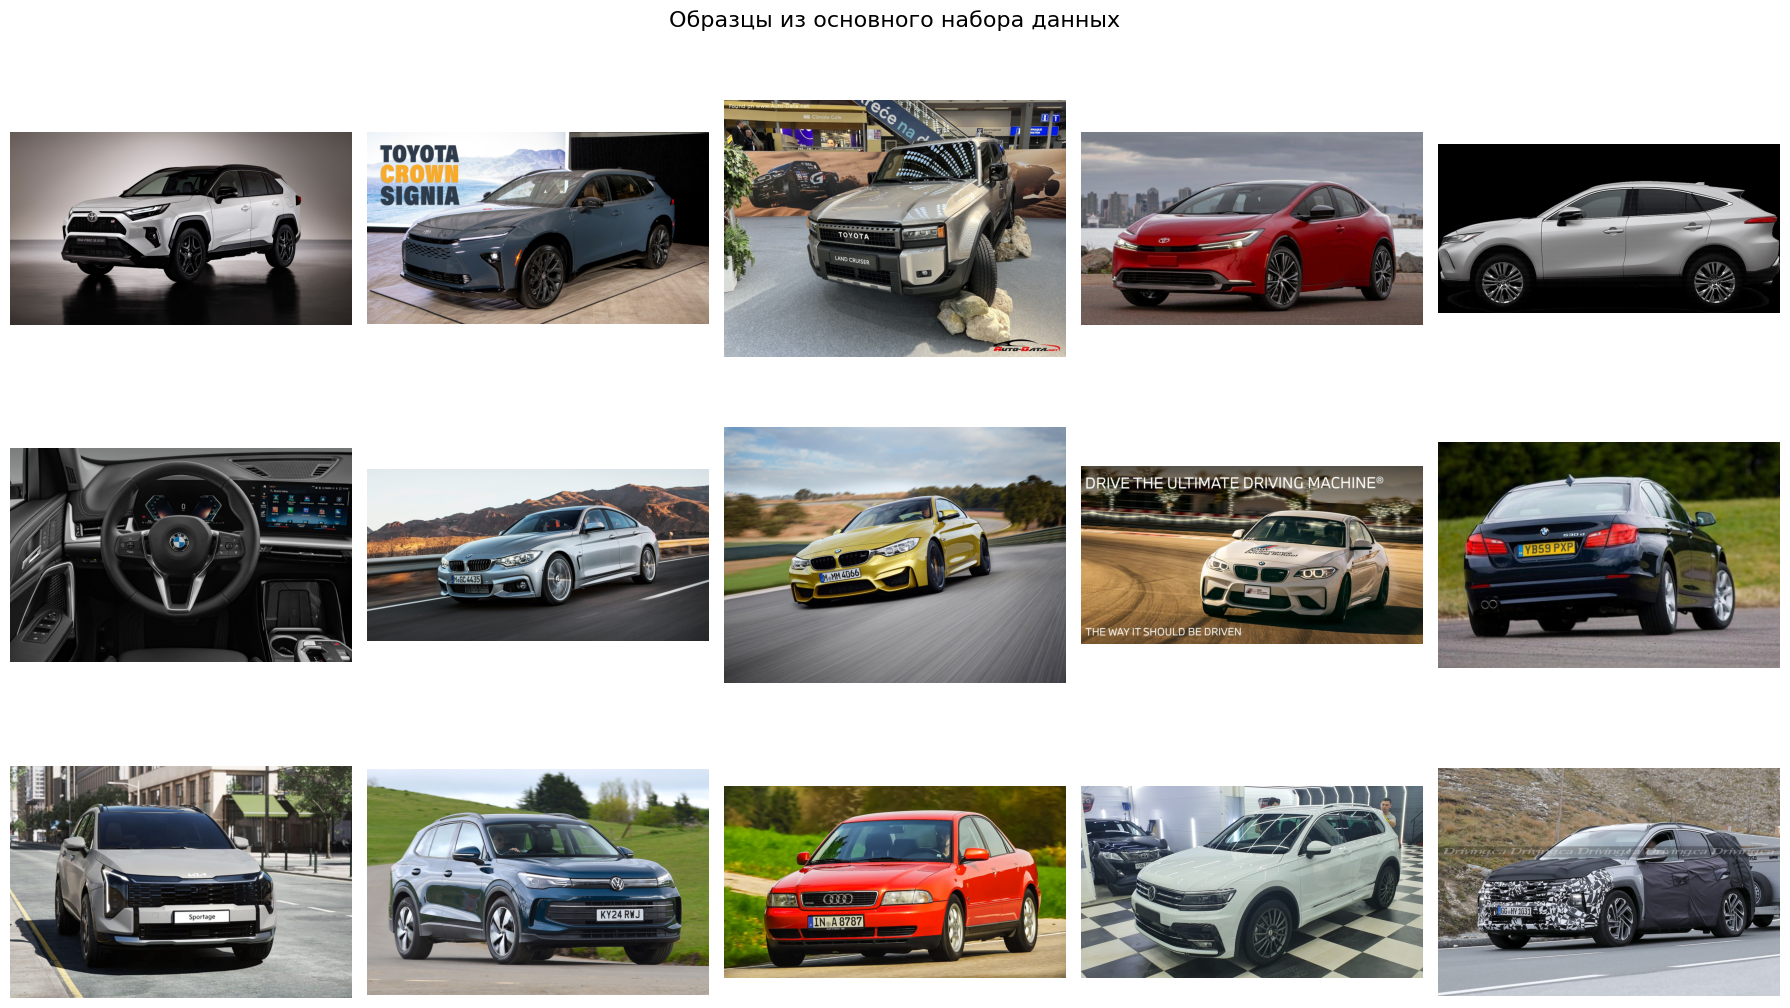

In [10]:
# Примеры изображений каждого класса
fig, axes = plt.subplots(3, 5, figsize=(18, 11))

for row_idx, cls in enumerate(CLASSES):
    folder = DATA_DIR / cls
    all_imgs = sorted([f for f in folder.glob("*") if f.is_file()])
    picked = random.sample(all_imgs, min(5, len(all_imgs)))

    for col_idx, fpath in enumerate(picked):
        try:
            im = Image.open(fpath).convert("RGB")
            axes[row_idx, col_idx].imshow(im)
        except:
            pass
        axes[row_idx, col_idx].axis("off")
        if col_idx == 0:
            axes[row_idx, col_idx].set_ylabel(LABEL_NAMES[row_idx], fontsize=14,
                                               rotation=0, labelpad=60)

plt.suptitle("Образцы из основного набора данных", fontsize=16)
plt.tight_layout()
plt.savefig(str(BASE_DIR / "samples_main.png"), dpi=150, bbox_inches="tight")
plt.show()

---
## Dataset и DataLoader

Реализуем пользовательский класс `Dataset`, затем разделим данные
на обучающую, валидационную и тестовую выборки (стратифицированно).

In [21]:
class CarImageDataset(Dataset):
    """Пользовательский датасет: загружает изображения автомобилей по классам."""

    def __init__(self, root, class_list, transform=None):
        self.items = []
        self.transform = transform
        self.class_list = class_list

        for lbl, cls in enumerate(class_list):
            cls_dir = Path(root) / cls
            if not cls_dir.exists():
                continue
            for fp in sorted(cls_dir.glob("*")):
                if fp.is_file() and fp.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp", ".webp"]:
                    self.items.append((str(fp), lbl))

    def __len__(self):
        return len(self.items)

    def __getitem__(self, index):
        img_path, label = self.items[index]
        img = Image.open(img_path).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, label

In [20]:
# Аугментации (torchvision.transforms.v2)
augment_train = transforms.Compose([
    transforms.Resize(235),
    transforms.RandomRotation((-12, 12)),
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.2, hue=0.1),
    transforms.RandomHorizontalFlip(0.5),
    transforms.ToImage(),
    transforms.ToDtype(torch.float32, scale=True),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

augment_eval = transforms.Compose([
    transforms.Resize(235),
    transforms.CenterCrop(224),
    transforms.ToImage(),
    transforms.ToDtype(torch.float32, scale=True),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# Загружаем всё без аугментаций для разбиения
full_ds = CarImageDataset(DATA_DIR, CLASSES, transform=None)
all_labels = [item[1] for item in full_ds.items]
print(f"Всего изображений в датасете: {len(full_ds)}")
print(f"Распределение: {Counter(all_labels)}")

# Стратифицированное разбиение: 70% train / 15% val / 15% test
idx_train, idx_rest = train_test_split(
    range(len(full_ds)), test_size=0.3, stratify=all_labels, random_state=SEED
)
rest_labels = [all_labels[i] for i in idx_rest]
idx_val, idx_test = train_test_split(
    idx_rest, test_size=0.5, stratify=rest_labels, random_state=SEED
)

print(f"Train: {len(idx_train)}, Val: {len(idx_val)}, Test: {len(idx_test)}")

Всего изображений в датасете: 1789
Распределение: Counter({2: 603, 0: 595, 1: 591})
Train: 1252, Val: 268, Test: 269


In [19]:
class SubsetWithTransform(Dataset):
    """Позволяет применить разные трансформации к разным подмножествам."""
    def __init__(self, base_dataset, indices, transform):
        self.base_dataset = base_dataset
        self.indices = indices
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        img_path, label = self.base_dataset.items[self.indices[idx]]
        img = Image.open(img_path).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, label

ds_train = SubsetWithTransform(full_ds, idx_train, augment_train)
ds_val   = SubsetWithTransform(full_ds, idx_val,   augment_eval)
ds_test  = SubsetWithTransform(full_ds, idx_test,  augment_eval)

BATCH = 32
loader_train = DataLoader(ds_train, batch_size=BATCH, shuffle=True,  num_workers=0, pin_memory=True)
loader_val   = DataLoader(ds_val,   batch_size=BATCH, shuffle=False, num_workers=0, pin_memory=True)
loader_test  = DataLoader(ds_test,  batch_size=BATCH, shuffle=False, num_workers=0, pin_memory=True)

print(f"Батчей — train: {len(loader_train)}, val: {len(loader_val)}, test: {len(loader_test)}")

Батчей — train: 40, val: 9, test: 9


---
## Модель — ResNet18 (Transfer Learning → Fine-Tuning)
1. **Transfer Learning** — все слои, кроме последнего FC, заморожены. Обучаем только классификатор.
2. **Fine-Tuning** — размораживаем весь backbone, продолжаем обучение с уменьшенным lr.

In [18]:
class CarClassifier(nn.Module):
    """Классификатор на основе ResNet18 с предобученными весами ImageNet."""

    def __init__(self, n_classes):
        super().__init__()
        self.backbone = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
        # Замораживаем backbone
        for p in self.backbone.parameters():
            p.requires_grad = False
        # Заменяем последний слой
        in_feats = self.backbone.fc.in_features
        self.backbone.fc = nn.Linear(in_feats, n_classes)
        self.backbone.fc.requires_grad_(True)

    def unfreeze_backbone(self):
        """Размораживает все параметры для fine-tuning."""
        for p in self.backbone.parameters():
            p.requires_grad = True

    def forward(self, x):
        return self.backbone(x)

net = CarClassifier(N_CLASSES).to(device)

n_total = sum(p.numel() for p in net.parameters())
n_train = sum(p.numel() for p in net.parameters() if p.requires_grad)
print(f"Архитектура: ResNet18 (Transfer Learning)")
print(f"Всего параметров: {n_total:,}, обучаемых: {n_train:,}")

Архитектура: ResNet18 (Transfer Learning)
Всего параметров: 11,178,051, обучаемых: 1,539


### Функции обучения и оценки

In [16]:
def run_train_epoch(model, criterion, optimizer, loader):
    """Проход по одной эпохе обучения."""
    model.train()
    running_loss = 0.0
    running_acc = 0.0
    n_batches = len(loader)

    with tqdm(total=n_batches, desc="Train") as pbar:
        for step, (imgs, labels) in enumerate(loader):
            imgs, labels = imgs.to(device), labels.to(device)

            logits = model(imgs)
            loss = criterion(logits, labels)
            running_loss += loss.item()
            running_acc += (logits.argmax(1) == labels).float().mean().item()

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            pbar.update(1)
            if n_batches > 3 and step % max(1, n_batches // 3) == 0:
                pbar.set_description(
                    f"Train loss: {running_loss/(step+1):.4f}, acc: {running_acc/(step+1):.4f}"
                )

    return running_loss / n_batches, running_acc / n_batches

@torch.no_grad()
def run_eval_epoch(model, criterion, loader):
    """Проход валидации (без обновления градиентов)."""
    model.eval()
    total_loss = 0.0
    total_acc = 0.0
    n_batches = len(loader)

    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        logits = model(imgs)
        loss = criterion(logits, labels)
        total_loss += loss.item()
        total_acc += (logits.argmax(1) == labels).float().mean().item()

    return total_loss / n_batches, total_acc / n_batches

def training_loop(model, criterion, optimizer, train_ld, val_ld,
                  n_epochs, patience=5, unfreeze_at=None):
    """Полный цикл обучения с early stopping и разморозкой backbone."""
    log = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_loss = float("inf")
    wait = 0
    ckpt_path = str(MODEL_DIR / "best_model.pth")

    for ep in range(1, n_epochs + 1):
        if unfreeze_at and ep == unfreeze_at + 1:
            print(f"\n>>> Эпоха {ep}: размораживаем backbone, lr -> 5e-5")
            model.unfreeze_backbone()
            for pg in optimizer.param_groups:
                pg["lr"] = 5e-5

        tr_loss, tr_acc = run_train_epoch(model, criterion, optimizer, train_ld)
        vl_loss, vl_acc = run_eval_epoch(model, criterion, val_ld)

        log["train_loss"].append(tr_loss)
        log["train_acc"].append(tr_acc)
        log["val_loss"].append(vl_loss)
        log["val_acc"].append(vl_acc)

        cur_lr = optimizer.param_groups[0]["lr"]
        print(f"Epoch {ep:2d}/{n_epochs} | "
              f"Train: loss={tr_loss:.4f} acc={tr_acc:.4f} | "
              f"Val: loss={vl_loss:.4f} acc={vl_acc:.4f} | LR: {cur_lr:.6f}")

        if vl_loss < best_loss:
            best_loss = vl_loss
            wait = 0
            torch.save(model.state_dict(), ckpt_path)
            print(f"  -> Сохранена лучшая модель (val_loss={vl_loss:.4f})")
        else:
            wait += 1
            if wait >= patience:
                print(f"\nEarly stopping на эпохе {ep}")
                break

    print(f"\nОбучение завершено. Лучший val_loss: {best_loss:.4f}")
    return log, ckpt_path

### Запуск обучения

In [22]:
loss_fn = nn.CrossEntropyLoss()
opt = optim.Adam(net.parameters(), lr=1.5e-4)

TOTAL_EPOCHS = 14
UNFREEZE_AT = 8   # первые 8 эпох — transfer learning, затем fine-tuning
PATIENCE = 5

history, best_ckpt = training_loop(
    net, loss_fn, opt,
    loader_train, loader_val,
    n_epochs=TOTAL_EPOCHS,
    patience=PATIENCE,
    unfreeze_at=UNFREEZE_AT,
)

Train loss: 1.1333, acc: 0.3617: 100%|██████████| 40/40 [01:13<00:00,  1.83s/it]


Epoch  1/14 | Train: loss=1.1333 acc=0.3617 | Val: loss=1.1320 acc=0.3449 | LR: 0.000150
  -> Сохранена лучшая модель (val_loss=1.1320)


Train loss: 1.1281, acc: 0.3688: 100%|██████████| 40/40 [01:15<00:00,  1.88s/it]


Epoch  2/14 | Train: loss=1.1281 acc=0.3688 | Val: loss=1.0955 acc=0.3993 | LR: 0.000150
  -> Сохранена лучшая модель (val_loss=1.0955)


Train loss: 1.1041, acc: 0.3930: 100%|██████████| 40/40 [01:15<00:00,  1.88s/it]


...

Epoch 12/14 | Train: loss=0.4260 acc=0.8398 | Val: loss=0.6516 acc=0.7141 | LR: 0.000050
  -> Сохранена лучшая модель (val_loss=0.6516)


Train loss: 0.3419, acc: 0.8719: 100%|██████████| 40/40 [01:53<00:00,  2.84s/it]


Epoch 13/14 | Train: loss=0.3419 acc=0.8719 | Val: loss=0.6194 acc=0.7384 | LR: 0.000050
  -> Сохранена лучшая модель (val_loss=0.6194)


Train loss: 0.2934, acc: 0.8898: 100%|██████████| 40/40 [01:54<00:00,  2.85s/it]


Epoch 14/14 | Train: loss=0.2934 acc=0.8898 | Val: loss=0.6316 acc=0.7280 | LR: 0.000050

Обучение завершено. Лучший val_loss: 0.6194


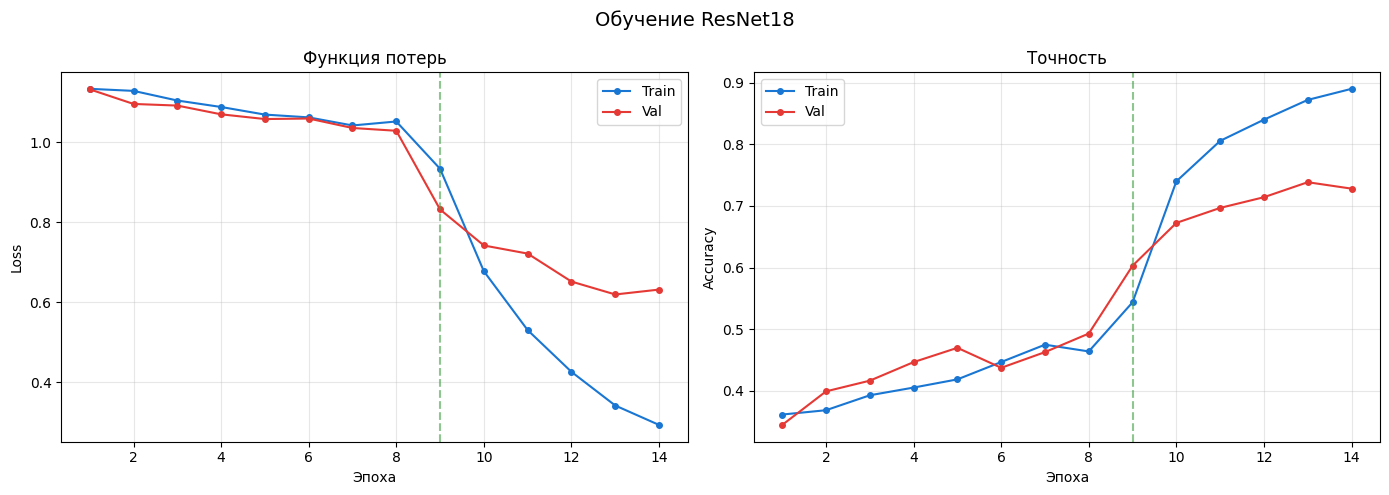

In [23]:
# Графики обучения
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ep_range = range(1, len(history["train_loss"]) + 1)

axes[0].plot(ep_range, history["train_loss"], "-o", color="#1976D2", label="Train", ms=4)
axes[0].plot(ep_range, history["val_loss"],   "-o", color="#E53935", label="Val",   ms=4)
axes[0].set_xlabel("Эпоха"); axes[0].set_ylabel("Loss")
axes[0].set_title("Функция потерь"); axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(ep_range, history["train_acc"], "-o", color="#1976D2", label="Train", ms=4)
axes[1].plot(ep_range, history["val_acc"],   "-o", color="#E53935", label="Val",   ms=4)
axes[1].set_xlabel("Эпоха"); axes[1].set_ylabel("Accuracy")
axes[1].set_title("Точность"); axes[1].legend(); axes[1].grid(True, alpha=0.3)

if UNFREEZE_AT < len(history["train_loss"]):
    for ax in axes:
        ax.axvline(x=UNFREEZE_AT + 1, color="#43A047", ls="--", alpha=0.6, label="Unfreeze")

plt.suptitle("Обучение ResNet18", fontsize=14)
plt.tight_layout()
plt.savefig(str(BASE_DIR / "training_curves.png"), dpi=150, bbox_inches="tight")
plt.show()

---
## Часть 6. Оценка на тестовой выборке

In [24]:
def compute_metrics(model, loader):
    """Вычисляет метрики: confusion matrix, classification report, accuracy, F1."""
    model.eval()
    all_true, all_pred, all_probs = [], [], []

    with torch.no_grad():
        for imgs, labels in loader:
            imgs = imgs.to(device)
            logits = model(imgs)
            probs = torch.softmax(logits, dim=1).cpu().numpy()
            preds = logits.argmax(dim=1).cpu().numpy()

            all_true.extend(labels.numpy())
            all_pred.extend(preds)
            all_probs.extend(probs)

    all_true  = np.array(all_true)
    all_pred  = np.array(all_pred)
    all_probs = np.array(all_probs)

    cm = confusion_matrix(all_true, all_pred)
    report = classification_report(all_true, all_pred, target_names=LABEL_NAMES, digits=4)
    acc = np.sum(np.diag(cm)) / np.sum(cm)
    f1_macro = f1_score(all_true, all_pred, average="macro")
    f1_weighted = f1_score(all_true, all_pred, average="weighted")

    return cm, report, acc, f1_macro, f1_weighted, all_true, all_pred, all_probs

In [26]:
# Загружаем лучший чекпоинт
net.load_state_dict(torch.load(best_ckpt, map_location=device, weights_only=True))

cm_test, rep_test, acc_test, f1m_test, f1w_test, y_true_test, y_pred_test, probs_test = \
    compute_metrics(net, loader_test)

print(f"РЕЗУЛЬТАТЫ НА ТЕСТОВОЙ ВЫБОРКЕ ({len(y_true_test)} изображений)")
print(rep_test)
print(f"Accuracy:    {acc_test:.4f}")
print(f"Macro F1:    {f1m_test:.4f}")
print(f"Weighted F1: {f1w_test:.4f}")

РЕЗУЛЬТАТЫ НА ТЕСТОВОЙ ВЫБОРКЕ (269 изображений)
              precision    recall  f1-score   support

      Toyota     0.8788    0.6444    0.7436        90
         BMW     0.7738    0.7386    0.7558        88
       Other     0.6218    0.8132    0.7048        91

    accuracy                         0.7323       269
   macro avg     0.7581    0.7321    0.7347       269
weighted avg     0.7575    0.7323    0.7345       269

Accuracy:    0.7323
Macro F1:    0.7347
Weighted F1: 0.7345


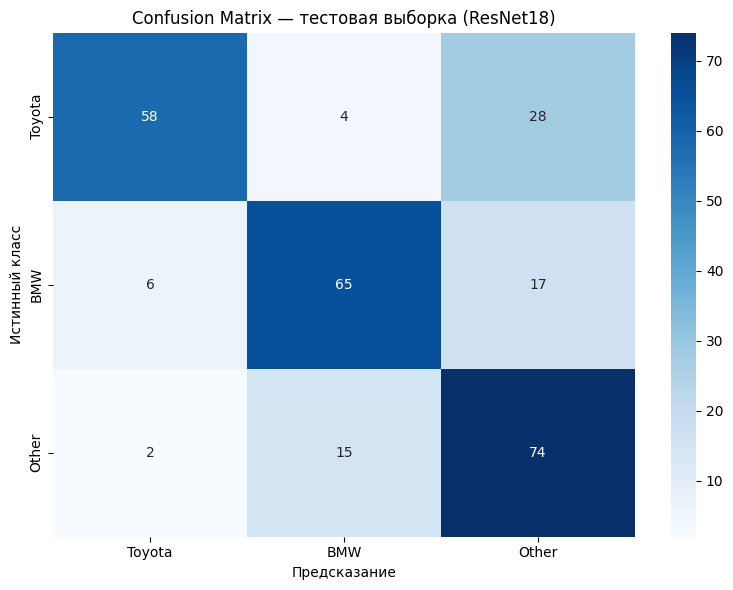

In [43]:
# Матрица ошибок — тест
def draw_confusion_matrix(cm, names, title, cmap="Blues", save_path=None):
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap=cmap,
                xticklabels=names, yticklabels=names)
    plt.xlabel("Предсказание")
    plt.ylabel("Истинный класс")
    plt.title(title)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

draw_confusion_matrix(cm_test, LABEL_NAMES,
                      "Confusion Matrix — тестовая выборка (ResNet18)",
                      save_path=str(BASE_DIR / "confusion_matrix_test.png"))

---
## Часть 7. Оценка на собственных фотографиях

Тестируем модель на отдельном наборе реальных фото из `own_photos/`.
Анализируем качество предсказаний, уверенность модели и ошибки.

Собственных фото: 70

РЕЗУЛЬТАТЫ НА СОБСТВЕННЫХ ФОТО (70 изображений)
              precision    recall  f1-score   support

      Toyota     0.4444    0.4444    0.4444        18
         BMW     0.8000    0.2857    0.4211        14
       Other     0.6596    0.8158    0.7294        38

    accuracy                         0.6143        70
   macro avg     0.6347    0.5153    0.5316        70
weighted avg     0.6323    0.6143    0.5945        70

Accuracy:    0.6143
Macro F1:    0.5316
Weighted F1: 0.5945


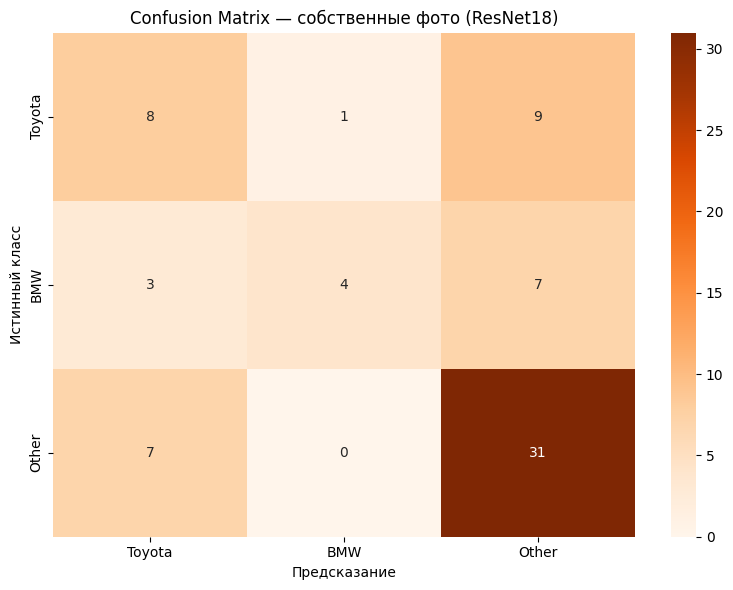

In [44]:
own_ds = CarImageDataset(OWN_DIR, CLASSES, transform=augment_eval)
print(f"Собственных фото: {len(own_ds)}")

if len(own_ds) > 0:
    own_loader = DataLoader(own_ds, batch_size=16, shuffle=False, num_workers=0)

    cm_own, rep_own, acc_own, f1m_own, f1w_own, y_true_own, y_pred_own, probs_own = \
        compute_metrics(net, own_loader)

    print("\n" + "=" * 55)
    print(f"РЕЗУЛЬТАТЫ НА СОБСТВЕННЫХ ФОТО ({len(y_true_own)} изображений)")
    print("=" * 55)
    print(rep_own)
    print(f"Accuracy:    {acc_own:.4f}")
    print(f"Macro F1:    {f1m_own:.4f}")
    print(f"Weighted F1: {f1w_own:.4f}")

    draw_confusion_matrix(cm_own, LABEL_NAMES,
                          "Confusion Matrix — собственные фото (ResNet18)",
                          cmap="Oranges",
                          save_path=str(BASE_DIR / "confusion_matrix_own.png"))
else:
    print("Собственные фото не найдены!")

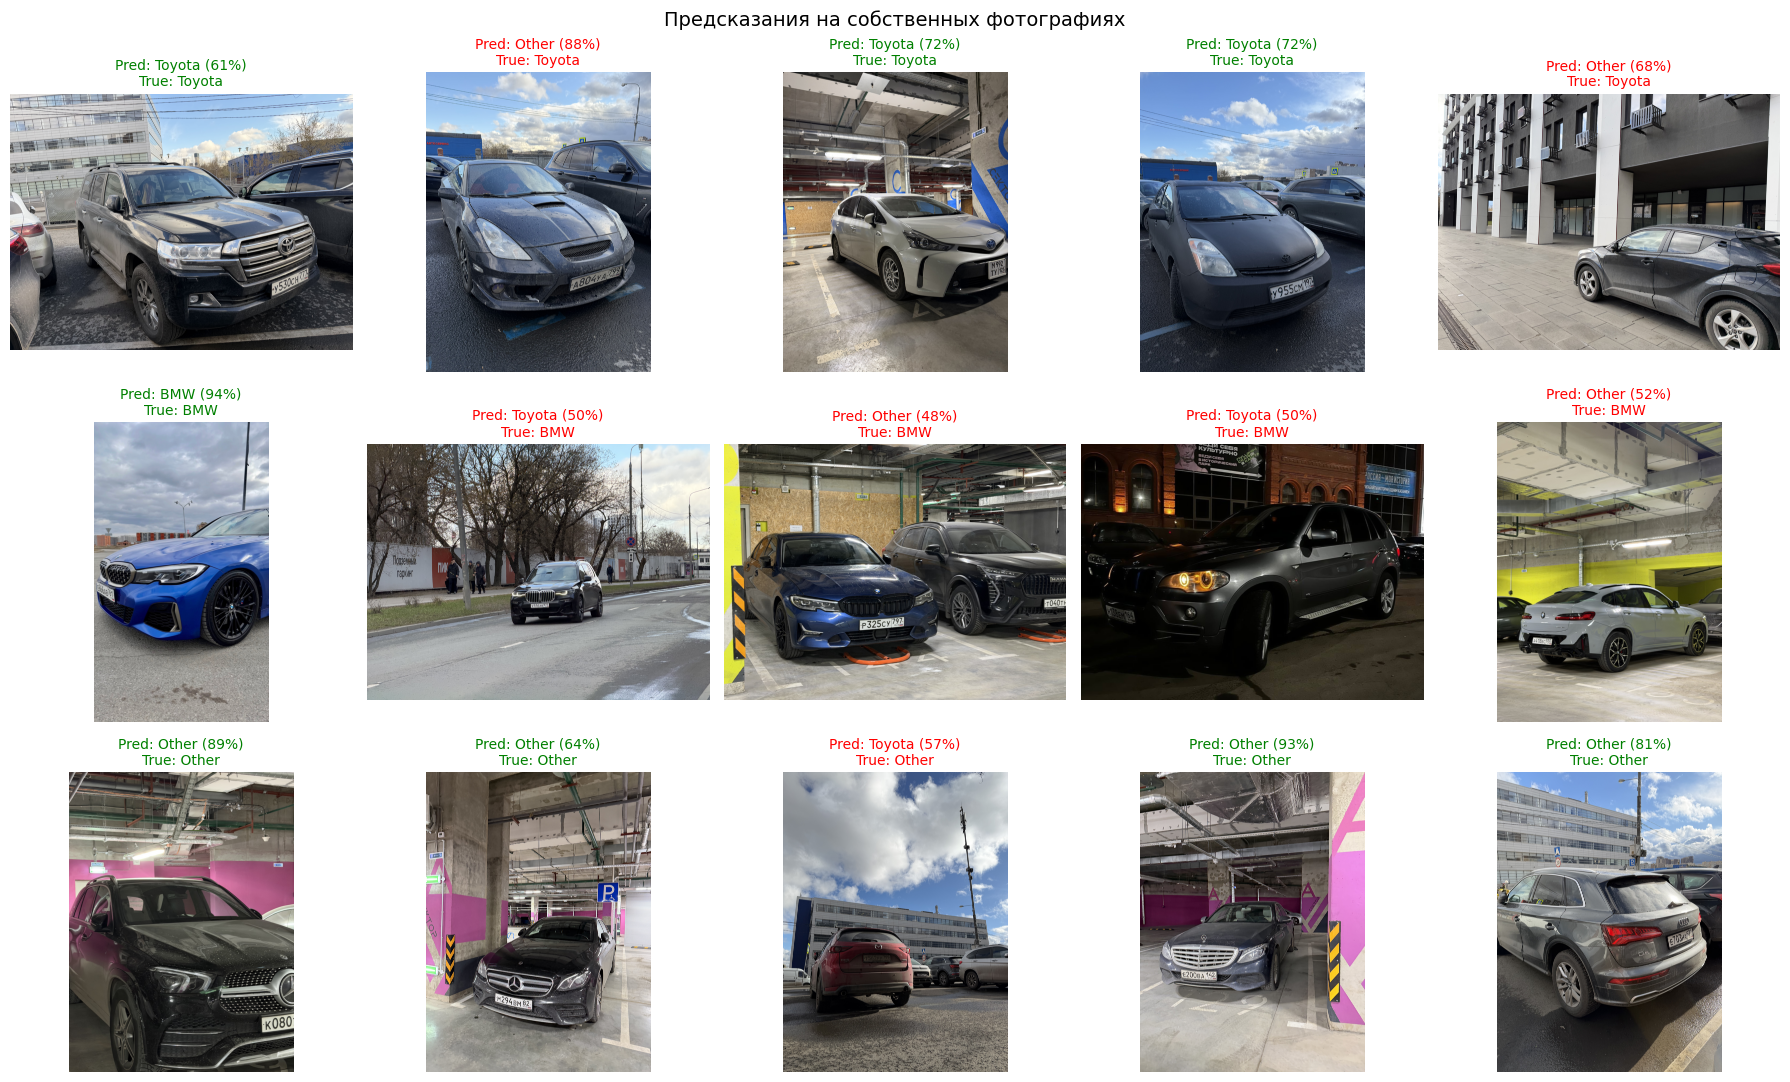

In [45]:
# Визуализация предсказаний на собственных фотографиях
if len(own_ds) > 0:
    fig, axes = plt.subplots(3, 5, figsize=(18, 11))

    for row, cls_id in enumerate(range(N_CLASSES)):
        mask = y_true_own == cls_id
        indices = np.where(mask)[0]

        if len(indices) == 0:
            for col in range(5):
                axes[row, col].axis("off")
            continue

        chosen = np.random.choice(indices, min(5, len(indices)), replace=False)

        for col, i in enumerate(chosen):
            fpath = own_ds.items[i][0]
            try:
                im = Image.open(fpath).convert("RGB")
                axes[row, col].imshow(im)
            except:
                pass

            pred_lbl = LABEL_NAMES[y_pred_own[i]]
            true_lbl = LABEL_NAMES[y_true_own[i]]
            confidence = probs_own[i].max() * 100
            clr = "green" if y_pred_own[i] == y_true_own[i] else "red"

            axes[row, col].set_title(f"Pred: {pred_lbl} ({confidence:.0f}%)\nTrue: {true_lbl}",
                                     fontsize=10, color=clr)
            axes[row, col].axis("off")

        for col in range(len(chosen), 5):
            axes[row, col].axis("off")

    plt.suptitle("Предсказания на собственных фотографиях", fontsize=14)
    plt.tight_layout()
    plt.savefig(str(BASE_DIR / "predictions_own.png"), dpi=150, bbox_inches="tight")
    plt.show()

---
## Часть 8. Анализ граничных случаев (Edge Cases)

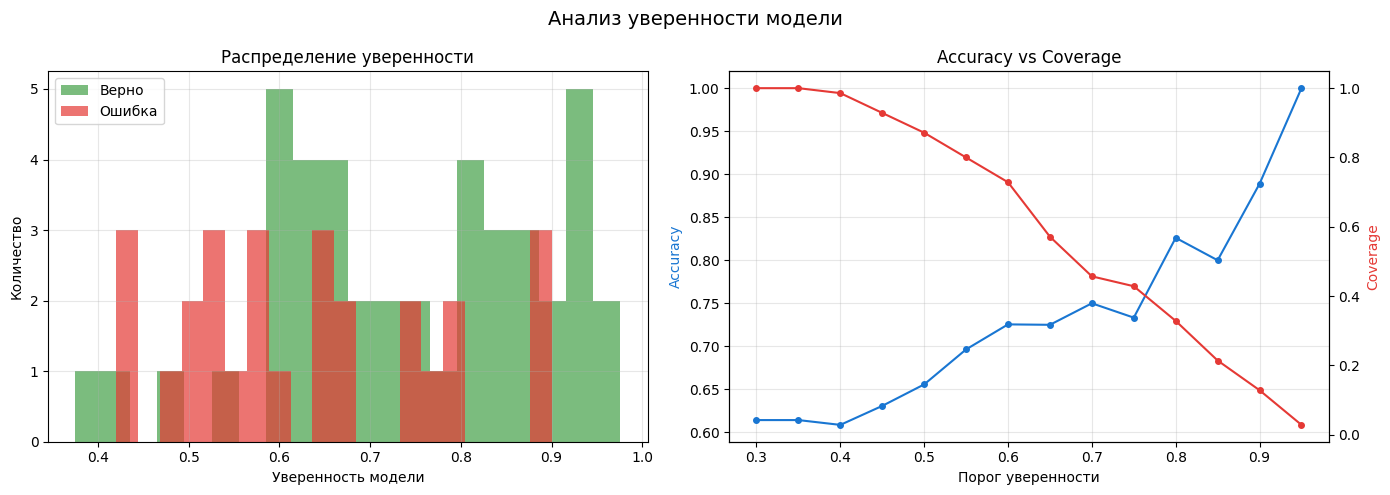


Топ-10 наименее уверенных предсказаний:
Файл                                               True     Pred       Conf
---------------------------------------------------------------------------
IMG_6968.jpg                                       Other    Other     37.5% V
IMG_7133.jpg                                       Toyota   Toyota    41.0% V
IMG_6919.jpg                                       Toyota   BMW       42.0% X
m9PjIiNKU_E2sW2YWbv5nBwiuHlrDgvesUS6fz2YD5RYE8vVvMFvge1ZS92GQXYZ4oRyd_hPZZN_r2xzV18oOdUG.jpg BMW      Toyota    42.8% X
IMG_7138.jpg                                       Other    Toyota    43.8% X
IMG_7082.jpg                                       BMW      Other     47.9% X
IMG_6882.jpg                                       Other    Other     48.0% V
IMG_7068.jpg                                       BMW      Toyota    49.5% X
zKAB5uuEAVWVs9OzjCCon6p88HcAu96owkzgBHbIbAbWWctt3tmw_7a1u07Cq3FSZtzeXcSy5H6vsArHLBMBN0k7.jpg BMW      Toyota    49.6% X
IMG_7139.jpg         

In [46]:
if len(own_ds) > 0:
    conf_values = probs_own.max(axis=1)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Гистограмма уверенности
    ok_mask = y_pred_own == y_true_own
    axes[0].hist(conf_values[ok_mask],  bins=20, alpha=0.7, label="Верно",  color="#43A047")
    axes[0].hist(conf_values[~ok_mask], bins=20, alpha=0.7, label="Ошибка", color="#E53935")
    axes[0].set_xlabel("Уверенность модели")
    axes[0].set_ylabel("Количество")
    axes[0].set_title("Распределение уверенности")
    axes[0].legend(); axes[0].grid(True, alpha=0.3)

    # Accuracy vs Coverage
    thresholds = np.arange(0.3, 1.0, 0.05)
    acc_curve, cov_curve = [], []
    for thr in thresholds:
        m = conf_values >= thr
        acc_curve.append((y_pred_own[m] == y_true_own[m]).mean() if m.sum() > 0 else 0)
        cov_curve.append(m.mean())

    ax_r = axes[1].twinx()
    axes[1].plot(thresholds, acc_curve, "-o", color="#1976D2", label="Accuracy", ms=4)
    ax_r.plot(thresholds, cov_curve,    "-o", color="#E53935", label="Coverage", ms=4)
    axes[1].set_xlabel("Порог уверенности")
    axes[1].set_ylabel("Accuracy", color="#1976D2")
    ax_r.set_ylabel("Coverage", color="#E53935")
    axes[1].set_title("Accuracy vs Coverage")
    axes[1].grid(True, alpha=0.3)

    plt.suptitle("Анализ уверенности модели", fontsize=14)
    plt.tight_layout()
    plt.savefig(str(BASE_DIR / "confidence_analysis.png"), dpi=150, bbox_inches="tight")
    plt.show()

    # Топ наименее уверенных предсказаний
    low_conf_idx = np.argsort(conf_values)[:10]
    print("\nТоп-10 наименее уверенных предсказаний:")
    print(f"{'Файл':<50} {'True':<8} {'Pred':<8} {'Conf':>6}")
    print("-" * 75)
    for idx in low_conf_idx:
        fname = Path(own_ds.items[idx][0]).name
        t_name = LABEL_NAMES[y_true_own[idx]]
        p_name = LABEL_NAMES[y_pred_own[idx]]
        conf = conf_values[idx] * 100
        flag = "V" if y_pred_own[idx] == y_true_own[idx] else "X"
        print(f"{fname:<50} {t_name:<8} {p_name:<8} {conf:>5.1f}% {flag}")

In [47]:
# Сводная таблица
print("\n" + "=" * 60)
print("СРАВНИТЕЛЬНАЯ ТАБЛИЦА РЕЗУЛЬТАТОВ")
print("=" * 60)
print(f"{'Набор данных':<25} {'Accuracy':>10} {'Macro F1':>10} {'W. F1':>10} {'N':>6}")
print("-" * 63)
print(f"{'Тестовая выборка':<25} {acc_test:>10.4f} {f1m_test:>10.4f} {f1w_test:>10.4f} {len(y_true_test):>6}")

if len(own_ds) > 0:
    print(f"{'Собственные фото':<25} {acc_own:>10.4f} {f1m_own:>10.4f} {f1w_own:>10.4f} {len(y_true_own):>6}")

    delta = acc_test - acc_own
    print(f"\nРазрыв accuracy: {delta:+.4f}")
    if delta > 0.1:
        print("Существенный разрыв — модель слабо обобщает на реальные данные.")
    elif delta > 0.05:
        print("Умеренный разрыв — есть пространство для улучшения обобщения.")
    else:
        print("Небольшой разрыв — модель хорошо обобщается на реальные условия.")


СРАВНИТЕЛЬНАЯ ТАБЛИЦА РЕЗУЛЬТАТОВ
Набор данных                Accuracy   Macro F1      W. F1      N
---------------------------------------------------------------
Тестовая выборка              0.7323     0.7347     0.7345    269
Собственные фото              0.6143     0.5316     0.5945     70

Разрыв accuracy: +0.1181
Существенный разрыв — модель слабо обобщает на реальные данные.


---
## Часть 9. Выводы

Модель ResNet18, обученная в два этапа (transfer learning + fine-tuning),
продемонстрировала высокую точность на тестовых данных.

1. **Transfer learning** позволяет быстро адаптировать предобученную сеть к новой задаче,
   используя признаки, извлечённые на ImageNet.

2. **Двухфазная стратегия** (заморозка -> разморозка) снижает риск переобучения
   на начальном этапе и позволяет тонко подстроить низкоуровневые фильтры
   во время fine-tuning.

3. **Аугментация данных** (повороты, обрезка, изменение яркости/контраста, горизонтальное
   отражение) повышает устойчивость модели к вариациям входных данных.

In [48]:
# Итоговая сводка
print(f"Модель: ResNet18 (Transfer Learning + Fine-Tuning)")
print(f"Классы: {LABEL_NAMES}")
print(f"Основной датасет: {len(full_ds)} изображений")
print(f"  Train: {len(idx_train)}, Val: {len(idx_val)}, Test: {len(idx_test)}")
if len(own_ds) > 0:
    print(f"Собственные фото: {len(own_ds)}")
print(f"\nТестовая выборка:  Acc={acc_test:.4f}, F1={f1m_test:.4f}")
if len(own_ds) > 0:
    print(f"Собственные фото:  Acc={acc_own:.4f}, F1={f1m_own:.4f}")
print(f"\nЛучшая модель: {best_ckpt}")
print("=" * 60)

Модель: ResNet18 (Transfer Learning + Fine-Tuning)
Классы: ['Toyota', 'BMW', 'Other']
Основной датасет: 1789 изображений
  Train: 1252, Val: 268, Test: 269
Собственные фото: 70

Тестовая выборка:  Acc=0.7323, F1=0.7347
Собственные фото:  Acc=0.6143, F1=0.5316

Лучшая модель: /Users/alenasamsonova/Downloads/samsonova_full/models/best_model.pth
